# Yield Curve Regimes & Equity Positioning
## Week 6: Do the results hold up?

**Research question:** How have U.S. stock sectors performed in each yield-curve environment since 1976, and what does today’s environment suggest about which sectors are best positioned?

Week 5 gave you 48 results and 4 standouts. A result worth betting money on should **still show up when you look at it in different ways**. If it vanishes the moment you change one small choice, it was probably luck or one unusual period.

This week runs **four checks** on the eight results that matter most:

| Check | What it protects against |
|---|---|
| 1. **Before vs. after 2000** | One era driving the whole result, or the world changing |
| 2. **Typical month, and without the 3 biggest months** | A few giant months creating the average (like Energy in Week 5) |
| 3. **A 6-month window instead of 3** | The 3-month rule being a lucky choice |
| 4. **Clear moves only** | Tiny, meaningless rate moves deciding a month’s label |

**How to run it:** upload it to [Google Colab](https://colab.research.google.com) (File → Upload notebook), then **Runtime → Run all**. It loads `monthly_dataset.csv`, your Week 1 data, from your GitHub repository, because checks 3 and 4 need to relabel every month.

### 1. Load your Week 1 dataset
**What this does:** reads your monthly yields and returns, and drops the newest month because it was downloaded partway through (the same as Week 3).

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle

GITHUB_CSV = "https://raw.githubusercontent.com/caden-smalls-greenwood/yield-curve-regimes/main/monthly_dataset.csv"
LOCAL_CSV  = Path("monthly_dataset.csv")
DATA = Path("data");    DATA.mkdir(exist_ok=True)
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)

def load_dataset():
    if LOCAL_CSV.exists():
        print("Using the monthly_dataset.csv already in this folder.")
        return pd.read_csv(LOCAL_CSV)
    try:
        r = requests.get(GITHUB_CSV, timeout=30)
        r.raise_for_status()
        print("Loaded monthly_dataset.csv from your GitHub repository.")
        return pd.read_csv(io.StringIO(r.text))
    except requests.RequestException as e:
        print(f"Couldn't reach GitHub ({type(e).__name__}). Click 'Choose Files' and pick monthly_dataset.csv.")
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError("Put monthly_dataset.csv in this notebook's folder and run this cell again.")
        uploaded = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

raw = load_dataset()
data = raw.set_index(pd.PeriodIndex(raw["month"], freq="M")).drop(columns="month")
DROP_LAST_MONTH = True                  # the newest month was only partly over when it was downloaded
if DROP_LAST_MONTH:
    data = data.iloc[:-1]

SECTORS = ["Nondurables", "Durables", "Manufacturing", "Energy", "Chemicals", "Tech",
           "Telecom", "Utilities", "Retail", "Healthcare", "Finance", "Other"]
REGIMES = ["Bull steepener", "Bear steepener", "Bull flattener", "Bear flattener"]
print(f"{len(data)} months, {data.index.min()} to {data.index.max()}")

Using the monthly_dataset.csv already in this folder.
604 months, 1976-06 to 2026-09


### 2. Your Week 3 and Week 4 steps, as two reusable tools
Checks 3 and 4 change how months get labeled, so the notebook needs to be able to redo the labeling. These two functions are exactly your Week 3 rule and your Week 4 pairing, with two settings you can change:
- `window`: how many months back to compare (Week 3 used **3**).
- `min_move`: the smallest change, in percentage points, that counts as a real move (Week 3 used **0**, so every change counted).

**The sanity check below matters:** with the Week 3 settings, the tools must give back exactly your Week 4 numbers (599 paired months; 133, 136, 156 and 174 per regime). If they don’t, something is wrong.

In [2]:
def label_regimes(window=3, min_move=0.0):
    """Week 3's rule. A month gets no label if a change is missing or smaller than min_move."""
    chg_10y   = (data["y10"] - data["y10"].shift(window)).round(4)
    chg_slope = (data["spread_10y2y"] - data["spread_10y2y"].shift(window)).round(4)
    level = np.where(chg_10y < 0, "Bull", "Bear")                 # yields falling = bull
    slope = np.where(chg_slope > 0, "steepener", "flattener")      # spread widening = steepener
    labels = pd.Series([f"{a} {b}" for a, b in zip(level, slope)], index=data.index)
    unclear = chg_10y.isna() | chg_slope.isna() | (chg_10y.abs() < min_move) | (chg_slope.abs() < min_move)
    return labels.mask(unclear)

def pair(labels):
    """Week 4's pairing: each month's returns next to the label known at the start of that month."""
    p = data[["Market"] + SECTORS].copy()
    p["regime_known"] = labels.shift(1)
    return p[p["regime_known"].notna() & p["Market"].notna()]

base = pair(label_regimes(window=3))
counts = base["regime_known"].value_counts().reindex(REGIMES)
print(f"Sanity check: {len(base)} paired months, {base.index.min()} to {base.index.max()}")
print(counts.to_string())
print("Matches Week 4:", len(base) == 599 and list(counts) == [133, 136, 156, 174])

Sanity check: 599 paired months, 1976-10 to 2026-08
regime_known
Bull steepener    133
Bear steepener    136
Bull flattener    156
Bear flattener    174
Matches Week 4: True


### 3. The eight results to test
- **The four Week 5 standouts** (t-stat beyond ±2).
- **The bear steepener results behind your Week 5 call**, because September 2026 was labeled a bear steepener: Durables (best), and Healthcare and Tech (worst). Manufacturing, the other “best,” is already a standout.
- **Energy after a bear flattener**, the spiky one from Week 5 question 5.

For each one, the notebook measures excess return (sector minus market, % per month) in every check.

In [3]:
KEY = [("Durables", "Bear flattener"), ("Manufacturing", "Bear steepener"), ("Other", "Bear flattener"),
       ("Telecom", "Bull steepener"), ("Durables", "Bear steepener"), ("Healthcare", "Bear steepener"),
       ("Tech", "Bear steepener"), ("Energy", "Bear flattener")]
NAMES = [f"{s} after a {r.lower()}" for s, r in KEY]

def excess(p, sector, regime):
    """Sector minus market, in % per month, for every month that followed this regime label."""
    return (p[sector] - p["Market"])[p["regime_known"] == regime] * 100

def summary(p, sector, regime):
    ex = excess(p, sector, regime)
    return ex.mean(), ex.mean() / (ex.std() / np.sqrt(len(ex))), len(ex)   # average, t-stat, months

values, tstats = {}, {}                  # filled in by each check below
values["Full sample"] = [summary(base, s, r)[0] for s, r in KEY]
tstats["Full sample"] = [summary(base, s, r)[1] for s, r in KEY]
pd.DataFrame({"Excess (% per month)": values["Full sample"], "t-stat": tstats["Full sample"]}, index=NAMES).round(2)

,Excess (% per month),t-stat
Durables after a bear flattener,-1.21,-3.29
Manufacturing after a bear steepener,0.55,2.53
Other after a bear flattener,-0.33,-2.47
Telecom after a bull steepener,-0.66,-2.23
Durables after a bear steepener,1.04,1.82
Healthcare after a bear steepener,-0.34,-1.39
Tech after a bear steepener,-0.17,-0.69
Energy after a bear flattener,0.65,1.52


### 4. Check 1: before vs. after 2000
The data splits into two halves of about 25 years each. If a result is real, it should show up in **both** halves, not just one.

First, how many months each regime had in each half. Fewer months means more wiggle room (a bigger ± range), so a result has to be bigger to stand out.

In [4]:
cut = pd.Period("2000-01", "M")
before, after = base[base.index < cut], base[base.index >= cut]
pd.DataFrame({"Before 2000": before["regime_known"].value_counts(),
              "2000 and after": after["regime_known"].value_counts()}).reindex(REGIMES)

,Before 2000,2000 and after
regime_known,,
Bull steepener,74,59
Bear steepener,48,88
Bull flattener,59,97
Bear flattener,98,76


In [5]:
for name, part in [("Before 2000", before), ("2000 and after", after)]:
    values[name] = [summary(part, s, r)[0] for s, r in KEY]
    tstats[name] = [summary(part, s, r)[1] for s, r in KEY]

pd.DataFrame({"Full sample": values["Full sample"], "Before 2000": values["Before 2000"], "t (before)": tstats["Before 2000"],
              "2000 and after": values["2000 and after"], "t (after)": tstats["2000 and after"]}, index=NAMES).round(2)

,Full sample,Before 2000,t (before),2000 and after,t (after)
Durables after a bear flattener,-1.21,-0.79,-2.43,-1.75,-2.40
Manufacturing after a bear steepener,0.55,0.10,0.36,0.80,2.65
Other after a bear flattener,-0.33,-0.30,-1.68,-0.36,-1.83
Telecom after a bull steepener,-0.66,-0.32,-0.90,-1.09,-2.19
Durables after a bear steepener,1.04,-0.04,-0.09,1.63,1.95
Healthcare after a bear steepener,-0.34,-0.13,-0.33,-0.45,-1.46
Tech after a bear steepener,-0.17,0.06,0.13,-0.30,-1.04
Energy after a bear flattener,0.65,0.40,0.91,0.98,1.21


### 5. Check 2: is it a few giant months?
Two ways to see past the giant months:
- **Typical month** (the median): line up every month from worst to best and take the one in the middle. One huge month can’t drag it around.
- **Without the 3 biggest months**: remove the three months that helped the result the most, then average again. For a negative result, those are its three worst months.

If the average only survives because of a few months, these numbers will shrink toward zero.

In [6]:
values["Typical month"] = [excess(base, s, r).median() for s, r in KEY]
trimmed, helpers = [], []
for s, r in KEY:
    ex = excess(base, s, r)
    biggest = ex.sort_values(ascending=ex.mean() < 0).index[:3]          # the 3 months that helped the result most
    trimmed.append(ex.drop(biggest).mean())
    helpers.append(", ".join(f"{m} ({ex[m]:+.0f})" for m in biggest))
values["Without 3 biggest months"] = trimmed

pd.DataFrame({"Full sample": values["Full sample"], "Typical month": values["Typical month"],
              "Without 3 biggest": trimmed, "The 3 biggest months (points vs. market)": helpers}, index=NAMES).round(2)

,Full sample,Typical month,Without 3 biggest,The 3 biggest months (points vs. market)
Durables after a bear flattener,-1.21,-1.25,-0.90,"2022-12 (-22), 2026-07 (-20), 2022-10 (-15)"
Manufacturing after a bear steepener,0.55,0.45,0.35,"2009-04 (+11), 2026-01 (+10), 2026-02 (+8)"
Other after a bear flattener,-0.33,-0.25,-0.24,"2026-04 (-6), 2026-05 (-5), 2006-07 (-5)"
Telecom after a bull steepener,-0.66,-0.77,-0.43,"2001-10 (-12), 2023-05 (-10), 2000-08 (-9)"
Durables after a bear steepener,1.04,0.74,0.45,"2009-04 (+34), 2021-10 (+24), 2024-11 (+23)"
Healthcare after a bear steepener,-0.34,-0.23,-0.13,"2009-04 (-11), 1999-04 (-10), 2024-11 (-7)"
Tech after a bear steepener,-0.17,0.04,0.00,"2002-02 (-11), 2002-12 (-7), 1985-03 (-6)"
Energy after a bear flattener,0.65,0.11,0.33,"2022-01 (+24), 2005-02 (+17), 2022-05 (+16)"


### 6. Check 3: a 6-month window
In Week 3 you picked a 3-month window. That was a reasonable choice, but not the only one. Here every month is relabeled using the change over the past **6 months** instead, then paired with next month’s returns the same way.

A real effect shouldn’t depend on that one choice. (It shouldn’t move hugely, either: a 6-month window reacts more slowly, so some labels change.)

In [7]:
labels3, labels6 = label_regimes(window=3), label_regimes(window=6)
both = labels3.notna() & labels6.notna()
print(f"The 6-month window gives a different label in {(labels3[both] != labels6[both]).mean():.0%} of months.\n")

six = pair(labels6)
values["6-month window"] = [summary(six, s, r)[0] for s, r in KEY]
tstats["6-month window"] = [summary(six, s, r)[1] for s, r in KEY]
pd.DataFrame({"Full sample (3-month)": values["Full sample"], "6-month window": values["6-month window"],
              "t (6-month)": tstats["6-month window"]}, index=NAMES).round(2)

The 6-month window gives a different label in 39% of months.



,Full sample (3-month),6-month window,t (6-month)
Durables after a bear flattener,-1.21,-0.82,-1.82
Manufacturing after a bear steepener,0.55,0.17,0.93
Other after a bear flattener,-0.33,-0.03,-0.18
Telecom after a bull steepener,-0.66,-0.54,-1.80
Durables after a bear steepener,1.04,-0.38,-0.83
Healthcare after a bear steepener,-0.34,0.20,0.84
Tech after a bear steepener,-0.17,-0.13,-0.53
Energy after a bear flattener,0.65,0.52,1.15


### 7. Check 4: clear moves only
Under the Week 3 rule, a month where the 10-year moved by just 0.01 percentage points still gets a label. A move that small is basically noise. This check only keeps months where **both** changes were at least **0.10 percentage points** (10 basis points), and drops the rest as “no clear regime.”

In [8]:
MIN_MOVE = 0.10
clear = pair(label_regimes(window=3, min_move=MIN_MOVE))
print(f"Months with a clear regime: {len(clear)} of {len(base)} ({len(base) - len(clear)} dropped as unclear)\n")

values["Clear moves only"] = [summary(clear, s, r)[0] for s, r in KEY]
tstats["Clear moves only"] = [summary(clear, s, r)[1] for s, r in KEY]
pd.DataFrame({"Full sample": values["Full sample"], "Clear moves only": values["Clear moves only"],
              "t (clear only)": tstats["Clear moves only"]}, index=NAMES).round(2)

Months with a clear regime: 369 of 599 (230 dropped as unclear)



,Full sample,Clear moves only,t (clear only)
Durables after a bear flattener,-1.21,-1.76,-3.16
Manufacturing after a bear steepener,0.55,0.43,1.49
Other after a bear flattener,-0.33,-0.21,-1.10
Telecom after a bull steepener,-0.66,-0.83,-2.35
Durables after a bear steepener,1.04,0.63,0.79
Healthcare after a bear steepener,-0.34,-0.02,-0.05
Tech after a bear steepener,-0.17,-0.28,-0.96
Energy after a bear flattener,0.65,0.72,1.26


### 8. The scorecard
Every check side by side. Each result gets one verdict, using the same rule for all of them:
- **Strong:** keeps the same direction in **every** check, and its t-stat is beyond ±2 in at least **2** of the 4 checks that have one.
- **Consistent but weak:** keeps the same direction in every check, but rarely stands out from luck.
- **Fragile:** **flips direction** in at least one check.

In [9]:
CHECKS = ["Full sample", "Before 2000", "2000 and after", "Typical month", "Without 3 biggest months",
          "6-month window", "Clear moves only"]
T_CHECKS = ["Before 2000", "2000 and after", "6-month window", "Clear moves only"]
scores = pd.DataFrame(values, index=NAMES)[CHECKS]
ts = pd.DataFrame(tstats, index=NAMES)

def verdict(name):
    row, full = scores.loc[name], scores.loc[name, "Full sample"]
    same_direction = all(np.sign(row[c]) == np.sign(full) for c in CHECKS[1:])
    strong_checks = sum(abs(ts.loc[name, c]) >= 2 for c in T_CHECKS)
    if not same_direction:
        return "Fragile"
    return "Strong" if strong_checks >= 2 else "Consistent but weak"

scores["Verdict"] = [verdict(n) for n in NAMES]
scores.round(2)

,Full sample,Before 2000,2000 and after,Typical month,Without 3 biggest months,6-month window,Clear moves only,Verdict
Durables after a bear flattener,-1.21,-0.79,-1.75,-1.25,-0.90,-0.82,-1.76,Strong
Manufacturing after a bear steepener,0.55,0.10,0.80,0.45,0.35,0.17,0.43,Consistent but weak
Other after a bear flattener,-0.33,-0.30,-0.36,-0.25,-0.24,-0.03,-0.21,Consistent but weak
Telecom after a bull steepener,-0.66,-0.32,-1.09,-0.77,-0.43,-0.54,-0.83,Strong
Durables after a bear steepener,1.04,-0.04,1.63,0.74,0.45,-0.38,0.63,Fragile
Healthcare after a bear steepener,-0.34,-0.13,-0.45,-0.23,-0.13,0.20,-0.02,Fragile
Tech after a bear steepener,-0.17,0.06,-0.30,0.04,0.00,-0.13,-0.28,Fragile
Energy after a bear flattener,0.65,0.40,0.98,0.11,0.33,0.52,0.72,Consistent but weak


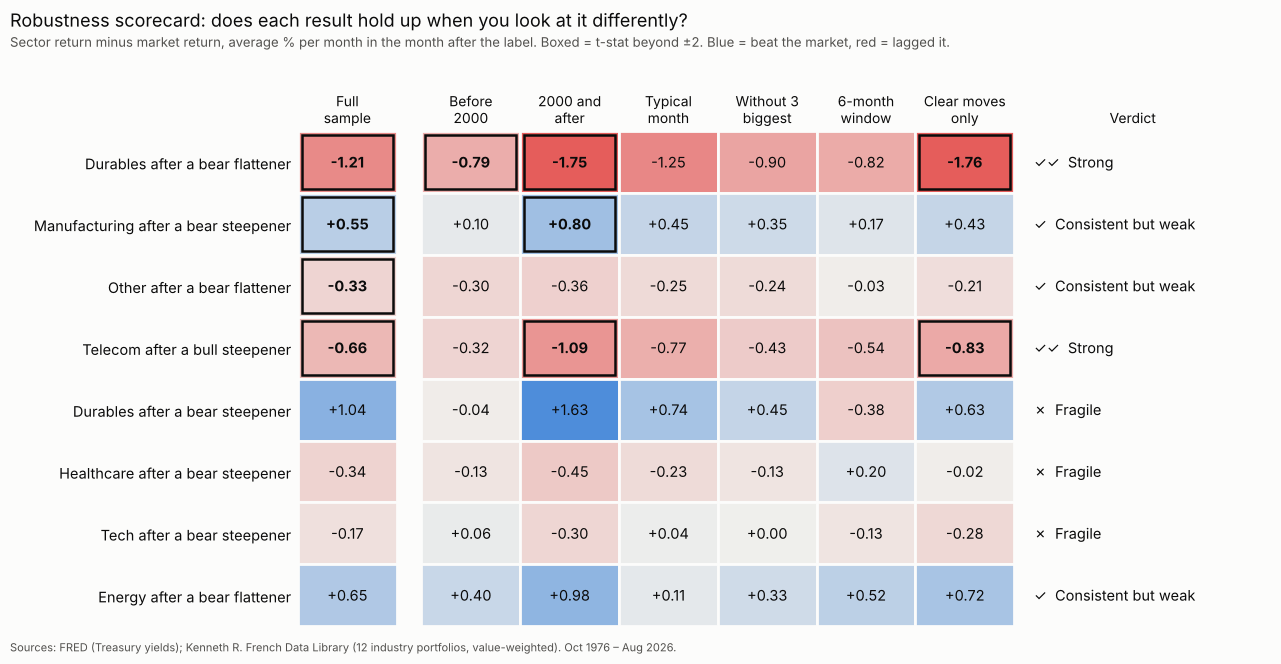

In [10]:
INK, MUTED, BG = "#0b0b0b", "#52514e", "#fcfcfb"
cmap = LinearSegmentedColormap.from_list("lag_to_beat", ["#e34948", "#f0efec", "#2a78d6"])
vals = scores[CHECKS].astype(float)
lim = np.ceil(np.abs(vals.values).max() * 4) / 4
norm = Normalize(-lim, lim)
xs = [0, 1.25, 2.25, 3.25, 4.25, 5.25, 6.25]                 # small gap after "Full sample"
MARK = {"Strong": "✓✓  Strong", "Consistent but weak": "✓  Consistent but weak", "Fragile": "✗  Fragile"}

fig, ax = plt.subplots(figsize=(13, 6.6), facecolor=BG)
ax.set_facecolor(BG)
for i, name in enumerate(vals.index):
    for j, col in enumerate(CHECKS):
        v = vals.loc[name, col]
        ax.add_patch(Rectangle((xs[j], i), 1, 1, facecolor=cmap(norm(v)), edgecolor=BG, linewidth=2))
        strong = col in ts.columns and abs(ts.loc[name, col]) >= 2
        if strong:
            ax.add_patch(Rectangle((xs[j] + 0.04, i + 0.06), 0.92, 0.88, fill=False, edgecolor=INK, linewidth=1.8))
        ax.text(xs[j] + 0.5, i + 0.5, f"{v:+.2f}", ha="center", va="center", fontsize=10.5, color=INK,
                fontweight="bold" if strong else "normal")
    ax.text(xs[-1] + 1.2, i + 0.5, MARK[scores.loc[name, "Verdict"]], va="center", fontsize=10.5, color=INK)

ax.set_xlim(-0.02, xs[-1] + 3.6)
ax.set_ylim(len(vals), 0)
ax.xaxis.tick_top()
ax.set_xticks([x + 0.5 for x in xs] + [xs[-1] + 2.2])
ax.set_xticklabels(["Full\nsample", "Before\n2000", "2000 and\nafter", "Typical\nmonth", "Without 3\nbiggest",
                    "6-month\nwindow", "Clear moves\nonly", "Verdict"], color=INK, fontsize=10)
ax.set_yticks([i + 0.5 for i in range(len(vals))])
ax.set_yticklabels(vals.index, color=INK, fontsize=10.5)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)

fig.suptitle("Robustness scorecard: does each result hold up when you look at it differently?",
             x=0.02, ha="left", color=INK, fontsize=13, y=0.985)
fig.text(0.02, 0.928, "Sector return minus market return, average % per month in the month after the label. "
         "Boxed = t-stat beyond ±2. Blue = beat the market, red = lagged it.", color=MUTED, fontsize=9.5)
fig.text(0.02, 0.012, "Sources: FRED (Treasury yields); Kenneth R. French Data Library (12 industry portfolios, value-weighted). "
         "Oct 1976 – Aug 2026.", color=MUTED, fontsize=8)
fig.subplots_adjust(left=0.24, right=0.99, top=0.80, bottom=0.05)
fig.savefig(FIGS / "robustness_scorecard.png", dpi=200, facecolor=BG)
plt.show()

### 9. Save the results
This writes `data/robustness_checks.csv` with every number from the scorecard. Upload it, `robustness_scorecard.png` and this notebook to your GitHub repository.

In [11]:
out = scores.copy()
for c in ts.columns:
    out[f"t-stat: {c}"] = ts[c]
out.index.name = "Result"
out.round(2).to_csv(DATA / "robustness_checks.csv")
print("Saved", DATA / "robustness_checks.csv", "-", len(out), "rows")

try:                                   # only works inside Google Colab
    from google.colab import files
    files.download(str(DATA / "robustness_checks.csv"))
    files.download(str(FIGS / "robustness_scorecard.png"))
except ImportError:
    print("Not running in Colab: find the files in the data/ and figures/ folders.")

Saved data/robustness_checks.csv - 8 rows
Not running in Colab: find the files in the data/ and figures/ folders.


### 10. Week 6 study questions
1. The top of this notebook says what each check protects against. Pick two checks, and for each one name a result on the scorecard that the check exposed and explain what it revealed.
2. Did Durables after a bear flattener hold up? Use numbers from at least three checks. How does this change your confidence compared with Week 5?
3. Durables after a bear steepener looked like the best sector for today’s regime in Week 5. What happened to it in the checks, and what drove its average? What does that mean for your Week 7 sector call?
4. Before 2000 there were only 48 bear steepener months; after 2000 there were 88. How does a smaller sample affect the ± range and the t-stat?
5. The 6-month window gave different answers for some results. Why would it be data snooping to pick whichever window gives the best-looking results? What should a researcher do instead?
6. In 2–3 sentences, what can you honestly claim from Weeks 5 and 6 if an interviewer asks, “What did you find?”

**Next (Week 7):** make the sector call. Check today’s regime with fresh data, weigh the evidence from Weeks 5 and 6, and pick the sector to overweight.